In [4]:
# imports and settings
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from tqdm.auto import tqdm
from pathlib import Path
import time

seed=42
np.random.seed(seed)
torch.manual_seed(seed)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

DATA_DIR= Path('../data')
Path('figures').mkdir(exist_ok=True)
Path('results').mkdir(exist_ok=True)

In [5]:
# MNIST, same split as Part 1
transform= transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,),(0.3081,))
])

mnist_train = datasets.MNIST(DATA_DIR,train=True,download=True,
                             transform=transform)
test_data= datasets.MNIST(DATA_DIR,train=False,download=True,
                          transform=transform)

train_data,val_data = random_split(
    mnist_train,[55000,5000],
    generator=torch.Generator().manual_seed(seed)
)

train_loader= DataLoader(train_data,batch_size=128,shuffle=True,
                         generator=torch.Generator().manual_seed(seed))
val_loader = DataLoader(val_data,batch_size=128,shuffle=False)
test_loader= DataLoader(test_data,batch_size=128,shuffle=False)

In [6]:
# split images into 49 patches of 4x4 pixels
def patchify(images,n_patches=7):
    n,c,h,w = images.shape
    assert h % n_patches == 0 and w % n_patches == 0

    ph,pw= h//n_patches,w//n_patches
    patches = images.reshape(n,c,n_patches,ph,n_patches,pw)
    patches= patches.permute(0,2,4,1,3,5)

    return patches.reshape(n,n_patches*n_patches,c*ph*pw)

In [7]:
# sinusoidal positional encoding
def get_positional_embeddings(length,d):
    positions= torch.arange(length,dtype=torch.float32).unsqueeze(1)
    frequencies = 10000 ** (torch.arange(0,d,2,dtype=torch.float32)/d)

    embeddings= torch.zeros(length,d)
    embeddings[:,0::2] = torch.sin(positions/frequencies)
    embeddings[:,1::2]= torch.cos(positions/frequencies[:d//2])

    return embeddings

In [8]:
# multi-head self-attention
class MultiHeadAttention(nn.Module):
    def __init__(self,d,n_heads=2):
        super().__init__()
        assert d % n_heads == 0

        self.n_heads= n_heads
        self.d_head = d//n_heads
        self.q = nn.Linear(d,d)
        self.k= nn.Linear(d,d)
        self.v = nn.Linear(d,d)
        self.proj= nn.Linear(d,d)

    def forward(self,x):
        n,t,d = x.shape

        q= self.q(x).reshape(n,t,self.n_heads,self.d_head).transpose(1,2)
        k = self.k(x).reshape(n,t,self.n_heads,self.d_head).transpose(1,2)
        v= self.v(x).reshape(n,t,self.n_heads,self.d_head).transpose(1,2)

        scores = (q @ k.transpose(-2,-1))/(self.d_head**0.5)
        attention= torch.softmax(scores,dim=-1)
        out = attention @ v

        out= out.transpose(1,2).reshape(n,t,d)
        return self.proj(out)

In [9]:
# transformer encoder block
class ViTBlock(nn.Module):
    def __init__(self,d,n_heads=2):
        super().__init__()
        self.norm1= nn.LayerNorm(d)
        self.attention = MultiHeadAttention(d,n_heads)
        self.norm2= nn.LayerNorm(d)

        self.mlp = nn.Sequential(
            nn.Linear(d,4*d),
            nn.GELU(),
            nn.Linear(4*d,d)
        )

    def forward(self,x):
        x= x + self.attention(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x

In [10]:
# Vision Transformer
class ViT(nn.Module):
    def __init__(self,d=32,n_heads=2,n_blocks=2,n_patches=7):
        super().__init__()
        assert 28 % n_patches == 0

        self.n_patches= n_patches
        patch_dim = (28//n_patches)**2
        self.embedding= nn.Linear(patch_dim,d)
        self.class_token = nn.Parameter(torch.randn(1,1,d))

        self.register_buffer('positions',
                             get_positional_embeddings(n_patches**2+1,d))

        self.blocks= nn.ModuleList([
            ViTBlock(d,n_heads) for _ in range(n_blocks)
        ])
        self.classifier = nn.Linear(d,10)

    def forward(self,images):
        patches= patchify(images,self.n_patches)
        tokens = self.embedding(patches)

        cls= self.class_token.expand(images.size(0),-1,-1)
        x = torch.cat((cls,tokens),dim=1)
        x= x + self.positions

        for block in self.blocks:
            x = block(x)

        return self.classifier(x[:,0])

In [11]:
# model and optimizer
torch.manual_seed(seed)

vit_model= ViT(d=32,n_heads=2,n_blocks=2).to(device)
criterion = nn.CrossEntropyLoss()
optimizer_vit= torch.optim.Adam(vit_model.parameters(),lr=0.001)

In [12]:
# train one epoch
def train_model(loader,model,criterion,optimizer):
    model.train()
    total_loss=0
    correct,total = 0,0

    for images,labels in loader:
        images= images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs= model(images)
        loss = criterion(outputs,labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()*labels.size(0)
        correct += (outputs.argmax(dim=1)==labels).sum().item()
        total += labels.size(0)

    return {'loss': total_loss/total,'accuracy': correct/total}

In [13]:
# validation and test
def evaluate_model(loader,model,criterion):
    model.eval()
    total_loss=0
    correct,total = 0,0
    actuals,predictions= [],[]

    with torch.no_grad():
        for images,labels in loader:
            images= images.to(device)
            labels = labels.to(device)

            outputs= model(images)
            loss = criterion(outputs,labels)
            predicted= outputs.argmax(dim=1)

            total_loss += loss.item()*labels.size(0)
            correct += (predicted==labels).sum().item()
            total += labels.size(0)

            actuals.extend(labels.cpu().tolist())
            predictions.extend(predicted.cpu().tolist())

    return {'loss': total_loss/total,'accuracy': correct/total,
            'targets': actuals,'predictions': predictions}

In [14]:
# train ViT
vit_history=[]
best_vit_loss = float('inf')
vit_training_time=0

for epoch in range(3):
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start= time.perf_counter()

    train_stats = train_model(
        tqdm(train_loader,desc=f'Epoch {epoch+1}'),
        vit_model,criterion,optimizer_vit
    )

    if device.type == 'cuda':
        torch.cuda.synchronize()
    vit_training_time += time.perf_counter()-start

    val_stats= evaluate_model(val_loader,vit_model,criterion)
    vit_history.append([epoch+1,train_stats['loss'],val_stats['loss'],
                        train_stats['accuracy'],val_stats['accuracy']])

    if val_stats['loss'] < best_vit_loss:
        best_vit_loss=val_stats['loss']
        torch.save(vit_model.state_dict(),'results/vit_best.pt')

    print(f"Loss: {train_stats['loss']:.4f}, val loss: {val_stats['loss']:.4f}, "
          f"val accuracy: {val_stats['accuracy']:.4f}")

vit_history = pd.DataFrame(vit_history,
                          columns=['epoch','train_loss','val_loss',
                                   'train_accuracy','val_accuracy'])
vit_history.to_csv('results/vit_history.csv',index=False)
print('Training time:',round(vit_training_time,2),'s')

Epoch 1:   0%|          | 0/430 [00:00<?, ?it/s]

Loss: 1.2996, val loss: 0.6243, val accuracy: 0.7966


Epoch 2:   0%|          | 0/430 [00:00<?, ?it/s]

Loss: 0.4518, val loss: 0.3881, val accuracy: 0.8724


Epoch 3:   0%|          | 0/430 [00:00<?, ?it/s]

Loss: 0.2936, val loss: 0.2492, val accuracy: 0.9214
Training time: 12.1 s


In [15]:
# test the saved ViT
vit_model.load_state_dict(torch.load('results/vit_best.pt',
                                    map_location=device,weights_only=True))

vit_test= evaluate_model(test_loader,vit_model,criterion)
y_true_vit = vit_test['targets']
y_pred_vit= vit_test['predictions']

vit_metrics = pd.DataFrame([{
    'model': 'ViT',
    'accuracy': accuracy_score(y_true_vit,y_pred_vit),
    'f1_macro': f1_score(y_true_vit,y_pred_vit,average='macro',zero_division=0),
    'f1_weighted': f1_score(y_true_vit,y_pred_vit,
                            average='weighted',zero_division=0),
    'loss': vit_test['loss'],
    'training_time_seconds': vit_training_time
}])

vit_metrics.to_csv('results/vit_metrics.csv',index=False)
print(vit_metrics.to_string(index=False))

model  accuracy  f1_macro  f1_weighted     loss  training_time_seconds
  ViT     0.928  0.926598     0.927912 0.225594              12.099939


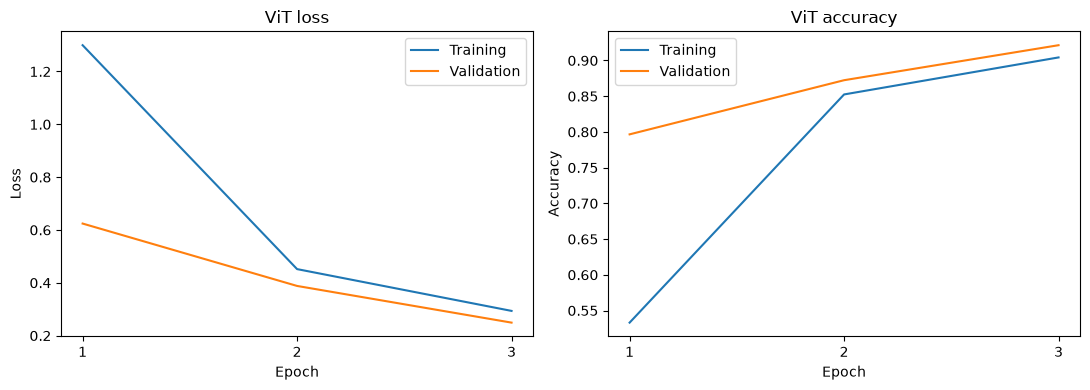

In [16]:
# ViT learning curves
fig,ax = plt.subplots(1,2,figsize=(11,4))

ax[0].plot(vit_history['epoch'],vit_history['train_loss'],label='Training')
ax[0].plot(vit_history['epoch'],vit_history['val_loss'],label='Validation')
ax[0].set_title('ViT loss')
ax[0].set_ylabel('Loss')

ax[1].plot(vit_history['epoch'],vit_history['train_accuracy'],label='Training')
ax[1].plot(vit_history['epoch'],vit_history['val_accuracy'],label='Validation')
ax[1].set_title('ViT accuracy')
ax[1].set_ylabel('Accuracy')

for a in ax:
    a.set_xlabel('Epoch')
    a.set_xticks(vit_history['epoch'])
    a.legend()

plt.tight_layout()
plt.savefig('figures/vit_learning_curves.png',dpi=300,bbox_inches='tight')
plt.show()

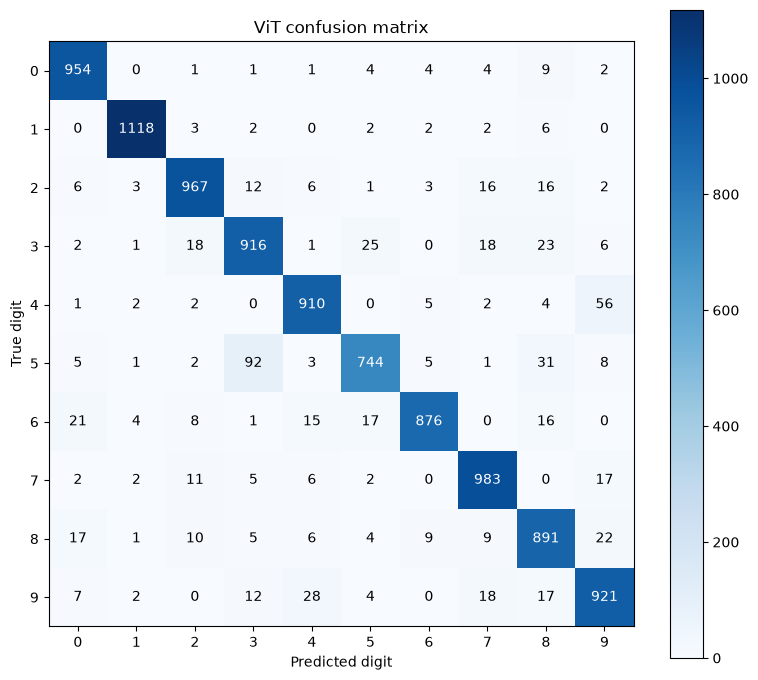

In [17]:
# ViT confusion matrix
cm= confusion_matrix(y_true_vit,y_pred_vit,labels=list(range(10)))
pd.DataFrame(cm).to_csv('results/vit_confusion_matrix.csv',
                        index_label='True digit')

fig,ax = plt.subplots(figsize=(8,7))
im= ax.imshow(cm,cmap='Blues')
fig.colorbar(im,ax=ax)

ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xlabel('Predicted digit')
ax.set_ylabel('True digit')
ax.set_title('ViT confusion matrix')

for i in range(10):
    for j in range(10):
        ax.text(j,i,str(cm[i,j]),ha='center',va='center',
                color='white' if cm[i,j]>cm.max()/2 else 'black')

plt.tight_layout()
plt.savefig('figures/vit_confusion_matrix.png',dpi=300,bbox_inches='tight')
plt.show()

In [18]:
# compare all models
files= ['cnn','rcnn','vgg16','alexnet','vit']
columns = ['model','accuracy','f1_macro','f1_weighted',
           'training_time_seconds']

comparison= pd.concat([
    pd.read_csv(f'results/{name}_metrics.csv')[columns]
    for name in files
],ignore_index=True)

comparison['epochs'] = [10,10,3,3,3]
comparison.to_csv('results/all_models_comparison.csv',index=False)
print(comparison.to_string(index=False))

       model  accuracy  f1_macro  f1_weighted  training_time_seconds  epochs
         CNN    0.9929  0.992847     0.992896              41.544190      10
Faster R-CNN    0.9890  0.988977     0.988982            2644.909476      10
       VGG16    0.9943  0.994246     0.994300             880.246967       3
     AlexNet    0.9903  0.990239     0.990298             212.156447       3
         ViT    0.9280  0.926598     0.927912              12.099939       3
